# PTB-XL Exploration

Working notes on PTB-XL: what the dataset contains, how rhythm labels are encoded, how bad the class
imbalance is, and the preprocessing needed to get a CNN-LSTM-ready dataset out of it.

Target classes are SR, AFIB, STACH, SBRAD. Final arrays are written to `processed_data/`.

## 1. Setup

In [1]:
import ast
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11})

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "archive/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1"

METADATA_PATH = DATA_DIR / "ptbxl_database.csv"
SCP_STATEMENTS_PATH = DATA_DIR / "scp_statements.csv"

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Metadata exists:", METADATA_PATH.exists())
print("SCP statements exist:", SCP_STATEMENTS_PATH.exists())
print("records100/ exists:", (DATA_DIR / "records100").exists())
print("records500/ exists:", (DATA_DIR / "records500").exists())

Project root: C:\Users\Shivank\Videos\ECG - GenAi
Data directory: C:\Users\Shivank\Videos\ECG - GenAi\archive\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1
Metadata exists: True
SCP statements exist: True
records100/ exists: True
records500/ exists: True


## 2. Dataset overview

One row per recording in `ptbxl_database.csv`. `filename_lr` is the 100 Hz copy, `filename_hr` the
500 Hz one. We use 100 Hz throughout.

In [2]:
metadata = pd.read_csv(METADATA_PATH)

sample_path = str(DATA_DIR / metadata.iloc[0]["filename_lr"])
sample_signal, sample_meta = wfdb.rdsamp(sample_path)

n_recordings = len(metadata)
n_patients = metadata["patient_id"].nunique()
fs = sample_meta["fs"]
n_samples = sample_signal.shape[0]
duration_s = n_samples / fs
n_leads = sample_signal.shape[1]
signal_shape = (n_leads, n_samples)  # after transpose convention

print("=" * 50)
print("PTB-XL DATASET OVERVIEW")
print("=" * 50)
print(f"  ECG recordings:       {n_recordings:,}")
print(f"  Unique patients:      {n_patients:,}")
print(f"  Sampling frequency:     {fs} Hz (100 Hz low-res records)")
print(f"  Recording duration:     {duration_s:.1f} s")
print(f"  Number of leads:        {n_leads}")
print(f"  Samples per recording:  {n_samples}")
print(f"  Signal shape (leads×T): {signal_shape}")
print(f"\n  Metadata columns ({len(metadata.columns)}):")
for col in metadata.columns:
    print(f"    - {col}")

PTB-XL DATASET OVERVIEW
  ECG recordings:       21,837
  Unique patients:      18,885
  Sampling frequency:     100 Hz (100 Hz low-res records)
  Recording duration:     10.0 s
  Number of leads:        12
  Samples per recording:  1000
  Signal shape (leads×T): (12, 1000)

  Metadata columns (28):
    - ecg_id
    - patient_id
    - age
    - sex
    - height
    - weight
    - nurse
    - site
    - device
    - recording_date
    - report
    - scp_codes
    - heart_axis
    - infarction_stadium1
    - infarction_stadium2
    - validated_by
    - second_opinion
    - initial_autogenerated_report
    - validated_by_human
    - baseline_drift
    - static_noise
    - burst_noise
    - electrodes_problems
    - extra_beats
    - pacemaker
    - strat_fold
    - filename_lr
    - filename_hr


In [3]:
print("First 5 rows (selected columns):")
display(metadata[["ecg_id", "patient_id", "age", "sex", "scp_codes", "strat_fold", "filename_lr"]].head())

print(f"\nRecordings per patient:")
recs_per_patient = metadata.groupby("patient_id").size()
print(recs_per_patient.describe())

print(f"\nPatients with multiple recordings: {(recs_per_patient > 1).sum():,} "
      f"({(recs_per_patient > 1).mean()*100:.1f}% of patients)")

First 5 rows (selected columns):


,ecg_id,patient_id,age,sex,scp_codes,strat_fold,filename_lr
0,1,15709.0,56.0,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",3,records100/00000/00001_lr
1,2,13243.0,19.0,0,"{'NORM': 80.0, 'SBRAD': 0.0}",2,records100/00000/00002_lr
2,3,20372.0,37.0,1,"{'NORM': 100.0, 'SR': 0.0}",5,records100/00000/00003_lr
3,4,17014.0,24.0,0,"{'NORM': 100.0, 'SR': 0.0}",3,records100/00000/00004_lr
4,5,17448.0,19.0,1,"{'NORM': 100.0, 'SR': 0.0}",4,records100/00000/00005_lr



Recordings per patient:
count    18885.000000
mean         1.156315
std          0.524680
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         10.000000
dtype: float64

Patients with multiple recordings: 2,127 (11.3% of patients)


In [4]:
print("Age distribution:")
print(metadata["age"].describe())
print(f"\nSex (0=female, 1=male):\n{metadata['sex'].value_counts()}")
print(f"\nMissing age: {metadata['age'].isnull().sum()}")
print(f"Missing sex: {metadata['sex'].isnull().sum()}")

Age distribution:
count    21748.000000
mean        59.836307
std         16.953125
min          2.000000
25%         50.000000
50%         62.000000
75%         72.000000
max         95.000000
Name: age, dtype: float64

Sex (0=female, 1=male):
sex
0    11379
1    10458
Name: count, dtype: int64

Missing age: 89
Missing sex: 0


**Observation:** Roughly 11% of patients have more than one recording, so the train/test split has to
be done at patient level rather than recording level.

Waveforms load through `wfdb`. Note the axis convention: `wfdb.rdsamp` returns time-first
`(1000, 12)`, and `load_ecg()` transposes it to leads-first `(12, 1000)`.

In [5]:
LEAD_NAMES = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]


def load_ecg(filename_lr: str):
    """Load one 100 Hz recording. Returns signal (12, n_samples) and wfdb metadata."""
    signal, meta = wfdb.rdsamp(str(DATA_DIR / filename_lr))
    return signal.T, meta


CHECK_N = min(100, len(metadata))
check_sample = metadata.sample(CHECK_N, random_state=RANDOM_SEED)

shapes, fs_set, durations = set(), set(), []
for _, row in check_sample.iterrows():
    sig, meta = load_ecg(row["filename_lr"])
    shapes.add(sig.shape)
    fs_set.add(meta["fs"])
    durations.append(sig.shape[1] / meta["fs"])

print(f"Checked {CHECK_N} recordings:")
print(f"  Unique signal shapes:  {shapes}")
print(f"  Sampling frequencies:  {fs_set}")
print(f"  Duration range (s):    {min(durations):.1f} – {max(durations):.1f}")
print(f"  Lead names from wfdb:  {sample_meta['sig_name']}")
print(f"  Units:                 {sample_meta['units']}")

Checked 100 recordings:
  Unique signal shapes:  {(12, 1000)}
  Sampling frequencies:  {100}
  Duration range (s):    10.0 – 10.0
  Lead names from wfdb:  ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
  Units:                 ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV']


**Observation:** Every checked record is 12 leads x 1000 samples at 100 Hz, i.e. exactly 10 s. No
resampling, cropping or padding needed.

## 3. Rhythm labels

There is no rhythm column. `scp_codes` holds a stringified dict of SCP code -> confidence, and rhythm
codes are the ones with `rhythm == 1` in `scp_statements.csv`. Confidences are frequently `0.0` for
rhythm codes, so they cannot be used to pick between competing labels.

In [6]:
metadata["scp_dict"] = metadata["scp_codes"].apply(ast.literal_eval)

print("Example scp_codes entries (raw string → parsed dict):\n")
for i in range(5):
    row = metadata.iloc[i]
    print(f"  ecg_id={row['ecg_id']}  report='{row['report'][:60]}...'")
    print(f"    scp_codes: {row['scp_dict']}")
    print()

Example scp_codes entries (raw string → parsed dict):

  ecg_id=1  report='sinusrhythmus periphere niederspannung...'
    scp_codes: {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}

  ecg_id=2  report='sinusbradykardie sonst normales ekg...'
    scp_codes: {'NORM': 80.0, 'SBRAD': 0.0}

  ecg_id=3  report='sinusrhythmus normales ekg...'
    scp_codes: {'NORM': 100.0, 'SR': 0.0}

  ecg_id=4  report='sinusrhythmus normales ekg...'
    scp_codes: {'NORM': 100.0, 'SR': 0.0}

  ecg_id=5  report='sinusrhythmus normales ekg...'
    scp_codes: {'NORM': 100.0, 'SR': 0.0}



In [7]:
scp = pd.read_csv(SCP_STATEMENTS_PATH, index_col=0)
print(f"Total SCP statement codes: {len(scp)}")
print(f"\nSCP statement columns: {list(scp.columns)}")
print(f"\nRhythm codes (rhythm == 1): {scp['rhythm'].eq(1.0).sum()}")
print(f"Diagnostic codes (diagnostic == 1): {scp['diagnostic'].eq(1.0).sum()}")
print(f"Form codes (form == 1): {scp['form'].eq(1.0).sum()}")

print("\n--- All rhythm SCP codes ---")
rhythm_scp = scp[scp["rhythm"] == 1.0][["description", "SCP-ECG Statement Description"]]
display(rhythm_scp)

Total SCP statement codes: 71

SCP statement columns: ['description', 'diagnostic', 'form', 'rhythm', 'diagnostic_class', 'diagnostic_subclass', 'Statement Category', 'SCP-ECG Statement Description', 'AHA code', 'aECG REFID', 'CDISC Code', 'DICOM Code']

Rhythm codes (rhythm == 1): 12
Diagnostic codes (diagnostic == 1): 44
Form codes (form == 1): 19

--- All rhythm SCP codes ---


,description,SCP-ECG Statement Description
SR,sinus rhythm,sinus rhythm
AFIB,atrial fibrillation,atrial fibrillation
STACH,sinus tachycardia,sinus tachycardia
SARRH,sinus arrhythmia,sinus arrhythmia
SBRAD,sinus bradycardia,sinus bradycardia
PACE,normal functioning artificial pacemaker,normal functioning artificial pacemaker
SVARR,supraventricular arrhythmia,supraventricular arrhythmia
BIGU,"bigeminal pattern (unknown origin, SV or Ventr...","bigeminal pattern (unknown origin, SV or Ventr..."
AFLT,atrial flutter,atrial flutter
SVTAC,supraventricular tachycardia,supraventricular tachycardia


Seven rhythm codes are plausible candidates. Counting their presence before committing to a label set.

In [8]:
CANDIDATE_RHYTHMS = ["SR", "AFIB", "SBRAD", "STACH", "AFLT", "SARRH", "SVTAC"]

print("Candidate rhythm classes and their SCP definitions:\n")
for code in CANDIDATE_RHYTHMS:
    if code in scp.index:
        row = scp.loc[code]
        print(f"  {code:6s}  rhythm={row['rhythm']}  diagnostic={row['diagnostic']}")
        print(f"         {row['description']}")
        print(f"         {row['SCP-ECG Statement Description']}")
    else:
        print(f"  {code:6s}  *** NOT FOUND in scp_statements.csv ***")
    print()

Candidate rhythm classes and their SCP definitions:

  SR      rhythm=1.0  diagnostic=nan
         sinus rhythm
         sinus rhythm

  AFIB    rhythm=1.0  diagnostic=nan
         atrial fibrillation
         atrial fibrillation

  SBRAD   rhythm=1.0  diagnostic=nan
         sinus bradycardia
         sinus bradycardia

  STACH   rhythm=1.0  diagnostic=nan
         sinus tachycardia
         sinus tachycardia

  AFLT    rhythm=1.0  diagnostic=nan
         atrial flutter
         atrial flutter

  SARRH   rhythm=1.0  diagnostic=nan
         sinus arrhythmia
         sinus arrhythmia

  SVTAC   rhythm=1.0  diagnostic=nan
         supraventricular tachycardia
         supraventricular tachycardia



In [9]:
# Rhythm presence = SCP code appears as a key; the confidence value is not used
def has_code(scp_dict, code):
    return code in scp_dict

rhythm_counts = {}
rhythm_examples = {}

for code in CANDIDATE_RHYTHMS:
    mask = metadata["scp_dict"].apply(lambda d: has_code(d, code))
    rhythm_counts[code] = mask.sum()
    examples = metadata[mask].head(3)[["ecg_id", "patient_id", "report", "scp_codes"]]
    rhythm_examples[code] = examples

print("Recordings containing each rhythm SCP code (as key in scp_codes):\n")
for code in CANDIDATE_RHYTHMS:
    print(f"  {code:6s}  {rhythm_counts[code]:,} recordings")
    display(rhythm_examples[code])
    print()

Recordings containing each rhythm SCP code (as key in scp_codes):

  SR      16,782 recordings


,ecg_id,patient_id,report,scp_codes
0,1,15709.0,sinusrhythmus periphere niederspannung,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
2,3,20372.0,sinusrhythmus normales ekg,"{'NORM': 100.0, 'SR': 0.0}"
3,4,17014.0,sinusrhythmus normales ekg,"{'NORM': 100.0, 'SR': 0.0}"



  AFIB    1,514 recordings


,ecg_id,patient_id,report,scp_codes
16,17,13619.0,vorhof:hf 280 tachykardes vorhofflimmern uebe...,"{'AFLT': 100.0, 'ABQRS': 0.0, 'AFIB': 0.0}"
151,152,9796.0,fÖrmaksflimmer/-fladder hÖger el-axel lÅga qrs...,"{'LMI': 50.0, 'ISCIL': 100.0, 'AFIB': 0.0}"
281,282,437.0,premature ventricular contraction(s). atrial f...,"{'ASMI': 100.0, 'ILBBB': 100.0, 'LVH': 50.0, '..."



  SBRAD   637 recordings


...

,ecg_id,patient_id,report,scp_codes
16,17,13619.0,vorhof:hf 280 tachykardes vorhofflimmern uebe...,"{'AFLT': 100.0, 'ABQRS': 0.0, 'AFIB': 0.0}"
17,18,13619.0,"vorhofflattern 2:1 Überleitung,jetzt nach isop...",{'AFLT': 100.0}
19,20,13619.0,supraventrikulÄre ersatzsystole(n) interponier...,"{'AFLT': 100.0, 'ABQRS': 0.0}"



  SARRH   772 recordings


,ecg_id,patient_id,report,scp_codes
10,11,11243.0,sinus arrhythmie sonst normales ekg,"{'NORM': 80.0, 'SARRH': 0.0}"
14,15,13375.0,sinus arrhythmie sonst normales ekg,"{'NORM': 100.0, 'SARRH': 0.0}"
36,37,9123.0,sinus arrhythmie sonst normales ekg,"{'NORM': 80.0, 'SARRH': 0.0}"



  SVTAC   27 recordings


,ecg_id,patient_id,report,scp_codes
335,336,449.0,"premature ventricular contraction(s) a rapid, ...","{'LVH': 100.0, 'ISC_': 100.0, 'PVC': 100.0, 'N..."
1032,1033,3161.0,regular supraventricular tachycardia. p waves ...,"{'ASMI': 50.0, 'LVH': 50.0, 'ISC_': 100.0, '1A..."
1172,1173,653.0,"a rapid, regular supraventricular tachycardia ...","{'AFLT': 100.0, 'SVTAC': 0.0}"


In [10]:
def count_rhythm_codes(scp_dict):
    return [c for c in CANDIDATE_RHYTHMS if c in scp_dict]

metadata["present_rhythms"] = metadata["scp_dict"].apply(count_rhythm_codes)
metadata["n_rhythm_codes"] = metadata["present_rhythms"].apply(len)

print("Number of candidate rhythm codes per recording:")
print(metadata["n_rhythm_codes"].value_counts().sort_index())

multi = metadata[metadata["n_rhythm_codes"] > 1]
print(f"\nRecordings with MULTIPLE rhythm codes: {len(multi)}")
if len(multi) > 0:
    print("\nExamples of co-occurring rhythm codes:")
    for _, row in multi.head(10).iterrows():
        print(f"  ecg_id={row['ecg_id']}  rhythms={row['present_rhythms']}  scp={row['scp_dict']}")

Number of candidate rhythm codes per recording:
n_rhythm_codes
0     1247
1    20549
2       41
Name: count, dtype: int64

Recordings with MULTIPLE rhythm codes: 41

Examples of co-occurring rhythm codes:
  ecg_id=17  rhythms=['AFIB', 'AFLT']  scp={'AFLT': 100.0, 'ABQRS': 0.0, 'AFIB': 0.0}
  ecg_id=284  rhythms=['SBRAD', 'SARRH']  scp={'LVH': 100.0, 'ISC_': 100.0, 'DIG': 100.0, 'VCLVH': 0.0, 'STD_': 0.0, 'SBRAD': 0.0, 'SARRH': 0.0}
  ecg_id=336  rhythms=['AFLT', 'SVTAC']  scp={'LVH': 100.0, 'ISC_': 100.0, 'PVC': 100.0, 'NST_': 0.0, 'AFLT': 0.0, 'SVTAC': 0.0}
  ecg_id=347  rhythms=['SR', 'AFLT']  scp={'LVH': 50.0, 'ISC_': 100.0, 'LAO/LAE': 50.0, '1AVB': 100.0, 'NST_': 0.0, 'LPR': 0.0, 'SR': 0.0, 'AFLT': 0.0}
  ecg_id=1173  rhythms=['AFLT', 'SVTAC']  scp={'AFLT': 100.0, 'SVTAC': 0.0}
  ecg_id=3505  rhythms=['AFLT', 'SVTAC']  scp={'ISC_': 100.0, '2AVB': 100.0, 'NST_': 0.0, 'AFLT': 0.0, 'SVTAC': 0.0}
  ecg_id=4769  rhythms=['AFIB', 'AFLT']  scp={'ISCIN': 100.0, 'AFIB': 0.0, 'AFLT': 0.0}
  

In [11]:
# Diagnostic codes are a separate annotation axis from rhythm codes
diag_scp = scp[scp["diagnostic"] == 1.0]

def get_diagnostic_classes(scp_dict):
    classes = set()
    for key in scp_dict:
        if key in diag_scp.index:
            classes.add(diag_scp.loc[key, "diagnostic_class"])
    return classes

metadata["diagnostic_classes"] = metadata["scp_dict"].apply(get_diagnostic_classes)

print("Diagnostic superclasses are SEPARATE from rhythm labels.")
print("Example: a recording can have rhythm=SR AND diagnostic=NORM simultaneously.\n")
print("Most common diagnostic class combinations:")
print(metadata["diagnostic_classes"].value_counts().head(10))

Diagnostic superclasses are SEPARATE from rhythm labels.
Example: a recording can have rhythm=SR AND diagnostic=NORM simultaneously.

Most common diagnostic class combinations:
diagnostic_classes
{NORM}         9083
{MI}           2538
{STTC}         2406
{CD}           1709
{CD, MI}       1302
{STTC, HYP}     783
{MI, STTC}      602
{HYP}           536
{CD, STTC}      472
{}              407
Name: count, dtype: int64


**Observation:** 41 recordings carry more than one candidate rhythm code, and diagnostic codes
(NORM, IMI, ...) sit alongside rhythm codes on most records. So rhythm labels need explicit
construction, not a lookup.

### Label rule

Four classes for the experiment: SR, AFIB, STACH, SBRAD. AFLT, SARRH and SVTAC are dropped as too
sparse or out of scope.

A recording is labelled only when **exactly one** of the four codes is present. Zero or more than one
means excluded. Ambiguous records are dropped rather than resolved, because the confidences are
unreliable and any priority ordering would be arbitrary.

In [12]:
import json

# Deterministic class order -> integer label mapping
FINAL_CLASSES = ["SR", "AFIB", "STACH", "SBRAD"]


def assign_final_label(scp_dict: dict):
    """Return (label, exclusion_reason). label is None when the record is excluded."""
    present = [c for c in FINAL_CLASSES if c in scp_dict]
    if len(present) == 0:
        return None, "no_target_rhythm"
    if len(present) > 1:
        return None, "conflicting_target_rhythms:" + ",".join(present)
    return present[0], None


_assigned = metadata["scp_dict"].apply(assign_final_label)
metadata["target_rhythm"] = _assigned.apply(lambda x: x[0])
metadata["exclusion_reason"] = _assigned.apply(lambda x: x[1])

labelled = metadata[metadata["target_rhythm"].notna()].copy()

n_conflict = int(metadata["exclusion_reason"].str.startswith("conflicting", na=False).sum())
n_no_target = int((metadata["exclusion_reason"] == "no_target_rhythm").sum())

print("=" * 55)
print("FINAL LABEL CONSTRUCTION (4 CLASSES)")
print("=" * 55)
print(f"  Total recordings:                {len(metadata):,}")
print(f"  Labelled (exactly one target):   {len(labelled):,}")
print(f"  Excluded — no target rhythm:     {n_no_target:,}")
print(f"  Excluded — conflicting targets:  {n_conflict:,}")

label_counts = labelled["target_rhythm"].value_counts().reindex(FINAL_CLASSES)
label_pct = (label_counts / len(labelled) * 100).round(2)
display(pd.DataFrame({"recordings": label_counts, "pct_of_labelled": label_pct}))

# Counts must reconstruct the labelled total
assert label_counts.sum() == len(labelled), "Class counts do not sum to labelled total"
assert len(labelled) + n_no_target + n_conflict == len(metadata), "Exclusion accounting mismatch"
print(f"\n  Consistency: {' + '.join(FINAL_CLASSES)} = {int(label_counts.sum()):,} = labelled total OK")

# Cross-check against the Week 1 numbers (informational, not asserted)
week1_reference = {"SR": 16782, "AFIB": 1514, "STACH": 826, "SBRAD": 637}
print("\n  Comparison with previously verified Week 1 counts:")
for cls in FINAL_CLASSES:
    got, exp = int(label_counts[cls]), week1_reference[cls]
    print(f"    {cls:6s} actual={got:6,}  week1={exp:6,}  {'match' if got == exp else 'DIFFERS — investigate'}")
print(f"    TOTAL  actual={len(labelled):6,}  week1={sum(week1_reference.values()):6,}")

FINAL LABEL CONSTRUCTION (4 CLASSES)
  Total recordings:                21,837
  Labelled (exactly one target):   19,759
  Excluded — no target rhythm:     2,078
  Excluded — conflicting targets:  0


,recordings,pct_of_labelled
target_rhythm,,
SR,16782,84.93
AFIB,1514,7.66
STACH,826,4.18
SBRAD,637,3.22



  Consistency: SR + AFIB + STACH + SBRAD = 19,759 = labelled total OK

  Comparison with previously verified Week 1 counts:
    SR     actual=16,782  week1=16,782  match
    AFIB   actual= 1,514  week1= 1,514  match
    STACH  actual=   826  week1=   826  match
    SBRAD  actual=   637  week1=   637  match
    TOTAL  actual=19,759  week1=19,759


**Observation:** 19,759 usable recordings and zero conflicts, so the exactly-one rule costs nothing
for these four classes. The 2,078 excluded records simply carry none of the four codes.

## 4. Class distribution

In [13]:
count_series = pd.Series(rhythm_counts).reindex(CANDIDATE_RHYTHMS)
pct_series = (count_series / n_recordings * 100).round(2)

dist_table = pd.DataFrame({"recordings": count_series, "pct_of_total": pct_series})
print("Rhythm class presence in annotations:\n")
display(dist_table)

has_any = metadata["n_rhythm_codes"] > 0
print(f"\nRecordings with ≥1 candidate rhythm code: {has_any.sum():,} ({has_any.mean()*100:.1f}%)")
print(f"Recordings with 0 candidate rhythm codes:  {(~has_any).sum():,}")

Rhythm class presence in annotations:



,recordings,pct_of_total
SR,16782,76.85
AFIB,1514,6.93
SBRAD,637,2.92
STACH,826,3.78
AFLT,73,0.33
SARRH,772,3.54
SVTAC,27,0.12



Recordings with ≥1 candidate rhythm code: 20,590 (94.3%)
Recordings with 0 candidate rhythm codes:  1,247


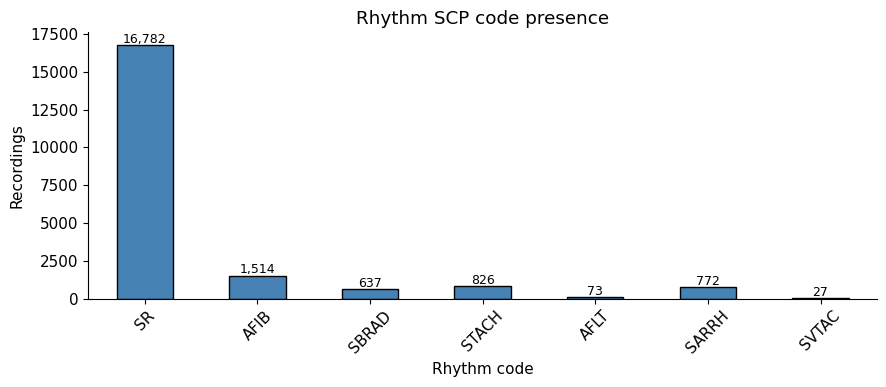

Imbalance: SR (16,782) vs SVTAC (27) = 621.6:1


In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
count_series.plot(kind="bar", ax=ax, color="steelblue", edgecolor="black")
ax.set_title("Rhythm SCP code presence")
ax.set_xlabel("Rhythm code")
ax.set_ylabel("Recordings")
ax.tick_params(axis="x", rotation=45)
for i, v in enumerate(count_series.values):
    ax.text(i, v + 150, f"{v:,}", ha="center", fontsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

max_class = count_series.idxmax()
min_class = count_series.idxmin()
ratio = count_series[max_class] / count_series[min_class]
print(f"Imbalance: {max_class} ({count_series[max_class]:,}) vs "
      f"{min_class} ({count_series[min_class]:,}) = {ratio:.1f}:1")

**Observation:** SR dominates at about 85% of the labelled set; SBRAD is the smallest of the four at
637. This imbalance, not data quality, is the main problem for the downstream classifier.

## 5. ECG examples

One full 12-lead record, then Lead II per rhythm class over the same 10 s window. Visual comparison
only - it says nothing about separability.

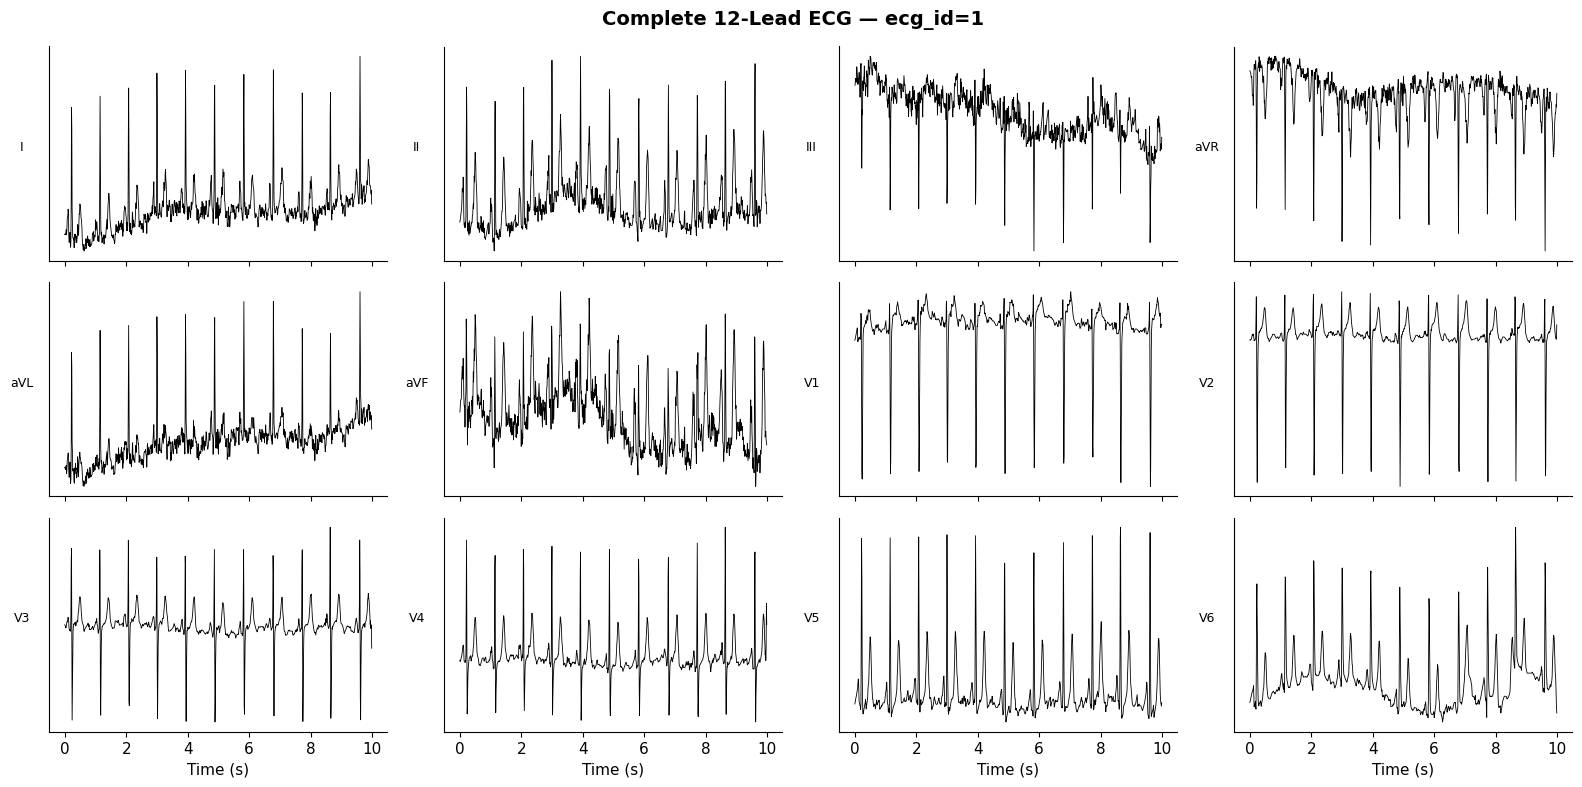

Signal shape: (12, 1000)  |  Duration: 10.0 s  |  Leads: 12


In [15]:
example_row = metadata.iloc[0]
sig, _ = load_ecg(example_row["filename_lr"])
t = np.arange(sig.shape[1]) / fs

fig, axes = plt.subplots(3, 4, figsize=(16, 8), sharex=True)
fig.suptitle(f"Complete 12-Lead ECG — ecg_id={example_row['ecg_id']}", fontsize=14, fontweight="bold")
for i, ax in enumerate(axes.flat):
    ax.plot(t, sig[i], linewidth=0.6, color="black")
    ax.set_ylabel(LEAD_NAMES[i], fontsize=9, rotation=0, labelpad=20)
    ax.set_yticks([])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

print(f"Signal shape: {sig.shape}  |  Duration: {sig.shape[1]/fs:.1f} s  |  Leads: {sig.shape[0]}")

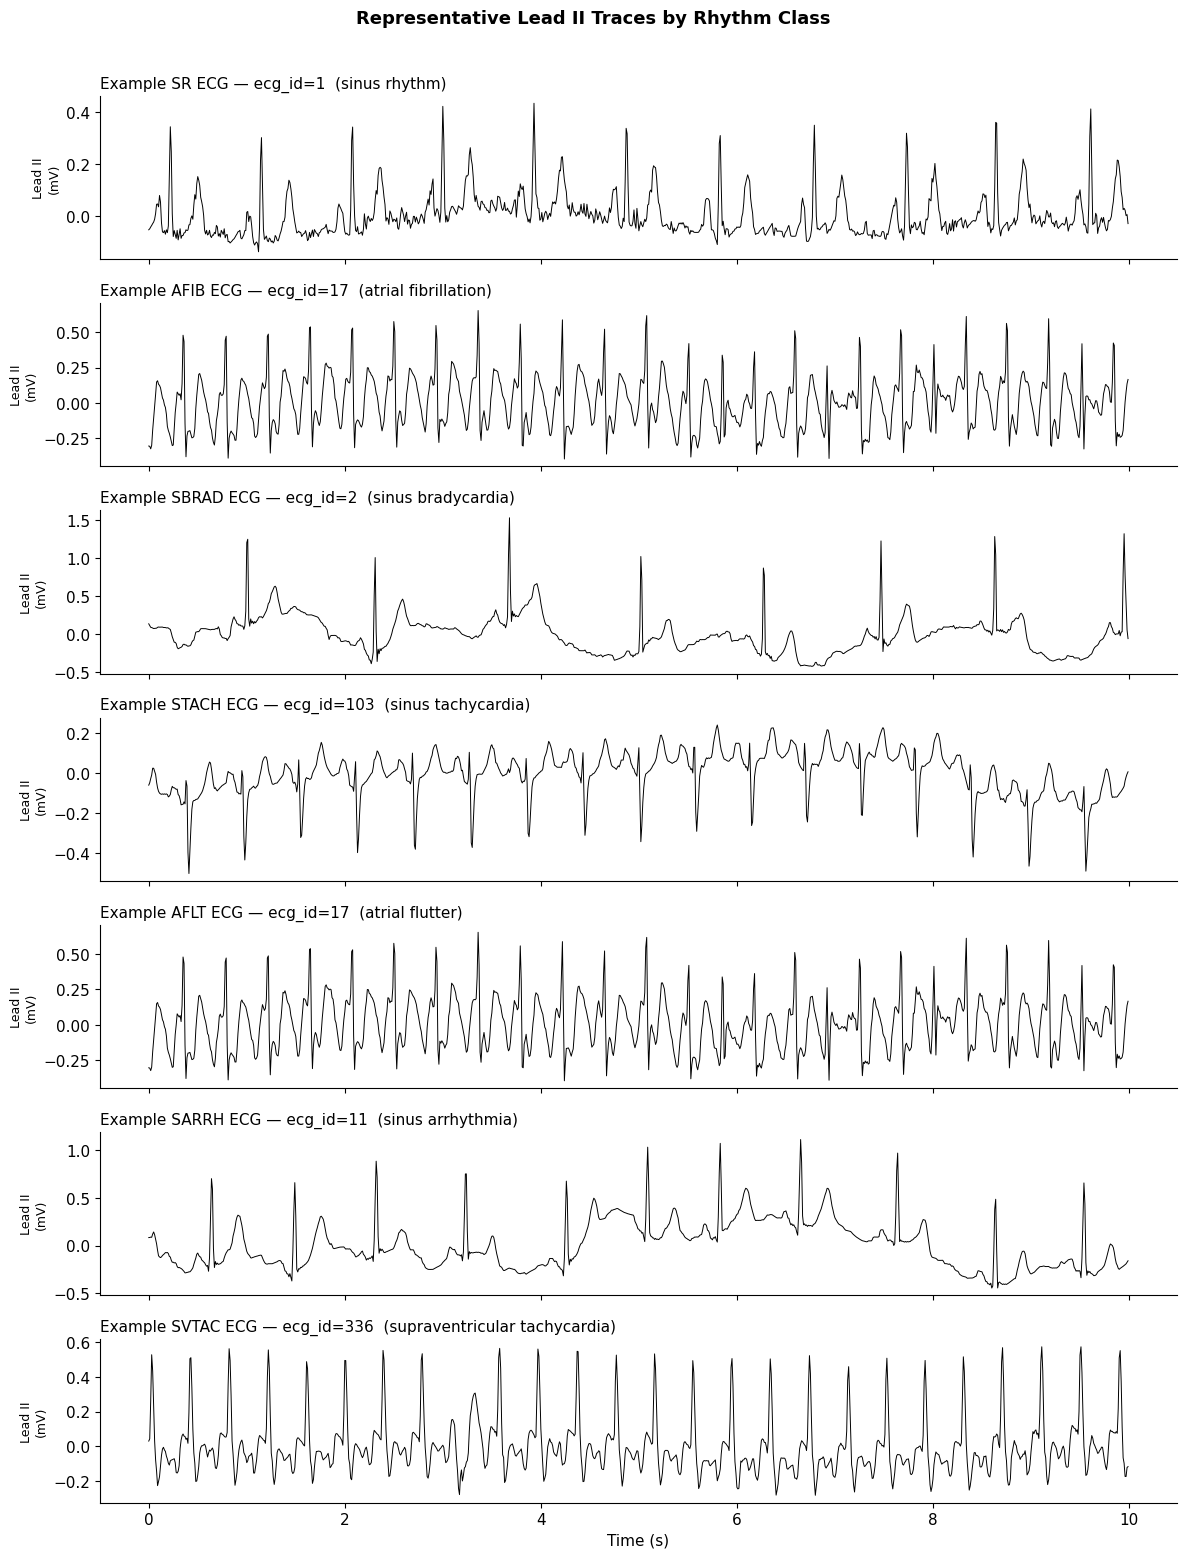

In [16]:
LEAD_IDX = 1  # Lead II
LEAD_LABEL = "Lead II"

fig, axes = plt.subplots(len(CANDIDATE_RHYTHMS), 1, figsize=(12, 2.2 * len(CANDIDATE_RHYTHMS)), sharex=True)

for i, code in enumerate(CANDIDATE_RHYTHMS):
    rows = metadata[metadata["scp_dict"].apply(lambda d: code in d)]
    if len(rows) == 0:
        axes[i].set_title(f"{code} — no recordings found")
        continue
    row = rows.iloc[0]
    sig, meta_i = load_ecg(row["filename_lr"])
    t_i = np.arange(sig.shape[1]) / meta_i["fs"]
    axes[i].plot(t_i, sig[LEAD_IDX], linewidth=0.7, color="black")
    axes[i].set_ylabel(f"{LEAD_LABEL}\n(mV)", fontsize=9)
    axes[i].set_title(f"Example {code} ECG — ecg_id={row['ecg_id']}  ({scp.loc[code, 'description']})",
                       fontsize=11, loc="left")
    axes[i].spines["top"].set_visible(False)
    axes[i].spines["right"].set_visible(False)

axes[-1].set_xlabel("Time (s)")
fig.suptitle(f"Representative {LEAD_LABEL} Traces by Rhythm Class", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

**Observation:** Rate and RR-interval regularity are the differences that are actually visible between
classes. Finer morphology is hard to judge at 100 Hz.

## 6. Signal QC

Per recording: missing file, NaN, Inf, length != 1000, zero-variance leads, peak amplitude > 50 mV.
Run on a random sample here for speed; the full pass over every retained record happens in Section 8.

In [17]:
def check_recording(row):
    """Quality check for one recording. Returns a dict of issues found."""
    result = {"ecg_id": row["ecg_id"], "patient_id": row["patient_id"]}
    filepath = DATA_DIR / row["filename_lr"]

    # Missing file
    if not filepath.with_suffix("").exists() and not Path(str(filepath) + ".dat").exists():
        # wfdb checks for .hea + .dat
        hea = Path(str(filepath) + ".hea")
        if not hea.exists():
            result["issue"] = "missing_file"
            return result

    try:
        sig, meta = load_ecg(row["filename_lr"])
    except Exception as e:
        result["issue"] = f"load_error: {e}"
        return result

    issues = []
    if np.isnan(sig).any():
        issues.append("has_nan")
    if np.isinf(sig).any():
        issues.append("has_inf")
    if sig.shape[1] != 1000:
        issues.append(f"unexpected_length_{sig.shape[1]}")
    flat_leads = int((sig.std(axis=1) == 0).sum())
    if flat_leads > 0:
        issues.append(f"flat_leads_{flat_leads}")
    if np.abs(sig).max() > 50:
        issues.append(f"high_amplitude_{np.abs(sig).max():.1f}mV")

    result["issue"] = ", ".join(issues) if issues else "ok"
    result["shape"] = sig.shape
    result["amp_min"] = float(sig.min())
    result["amp_max"] = float(sig.max())
    return result


# Check a random sample for speed (full check on all ~22k takes several minutes)
QC_SAMPLE = min(500, len(metadata))
qc_sample = metadata.sample(QC_SAMPLE, random_state=RANDOM_SEED)
print(f"Running quality checks on {QC_SAMPLE} random recordings...\n")

qc_results = pd.DataFrame([check_recording(row) for _, row in qc_sample.iterrows()])

print("Issue summary:")
print(qc_results["issue"].value_counts())
print(f"\nAmplitude range across checked recordings:")
ok = qc_results[qc_results["issue"] == "ok"]
if len(ok) > 0:
    print(f"  min: {ok['amp_min'].min():.3f} mV")
    print(f"  max: {ok['amp_max'].max():.3f} mV")

problems = qc_results[qc_results["issue"] != "ok"]
print(f"\nProblematic recordings in sample: {len(problems)} / {QC_SAMPLE}")
if len(problems) > 0:
    display(problems.head(10))

Running quality checks on 500 random recordings...



Issue summary:
issue
ok    500
Name: count, dtype: int64

Amplitude range across checked recordings:
  min: -7.185 mV
  max: 6.584 mV

Problematic recordings in sample: 0 / 500


In [18]:
# Missing labels check
print("Missing scp_codes:", metadata["scp_codes"].isnull().sum())
print("Empty scp_codes dicts:", metadata["scp_dict"].apply(len).eq(0).sum())
print("Missing filename_lr:", metadata["filename_lr"].isnull().sum())
print("Missing patient_id:", metadata["patient_id"].isnull().sum())

Missing scp_codes: 0
Empty scp_codes dicts: 0
Missing filename_lr: 0
Missing patient_id: 0


**Observation:** 0 of 500 flagged, amplitudes stay within about +/-7 mV (well under the 50 mV bound),
and no metadata fields are missing. PTB-XL at 100 Hz needs very little repair.

## 7. Patient-level split

Patients can have several recordings, and some span different rhythm codes, so a recording-level split
would leak patient identity into the test set. The `strat_fold` column is also recording-level and does
not guarantee patient disjointness.

In [19]:
recs_per_patient = metadata.groupby("patient_id").size()

print("=" * 50)
print("PATIENT-LEVEL SPLITTING ANALYSIS")
print("=" * 50)
print(f"  Total patients:                {len(recs_per_patient):,}")
print(f"  Patients with 1 recording:     {(recs_per_patient == 1).sum():,}")
print(f"  Patients with 2+ recordings:   {(recs_per_patient > 1).sum():,}")
print(f"  Max recordings per patient:    {recs_per_patient.max()}")
print(f"  Mean recordings per patient:   {recs_per_patient.mean():.2f}")

print(f"\n  Distribution of recordings per patient:")
print(recs_per_patient.value_counts().sort_index().head(10))

PATIENT-LEVEL SPLITTING ANALYSIS
  Total patients:                18,885
  Patients with 1 recording:     16,758
  Patients with 2+ recordings:   2,127
  Max recordings per patient:    10
  Mean recordings per patient:   1.16

  Distribution of recordings per patient:
1     16758
2      1604
3       348
4       103
5        43
6        16
7         5
8         4
9         3
10        1
Name: count, dtype: int64


In [20]:
# Can a patient have recordings with DIFFERENT rhythm codes?
def primary_rhythms_for_patient(patient_rows):
    all_rhythms = set()
    for _, row in patient_rows.iterrows():
        for c in CANDIDATE_RHYTHMS:
            if c in row["scp_dict"]:
                all_rhythms.add(c)
    return all_rhythms

patient_rhythm_sets = metadata.groupby("patient_id").apply(
    lambda g: primary_rhythms_for_patient(g), include_groups=False
)
patient_n_rhythms = patient_rhythm_sets.apply(len)

print("Rhythm codes per patient (across all their recordings):")
print(patient_n_rhythms.value_counts().sort_index())

multi_rhythm_patients = patient_rhythm_sets[patient_n_rhythms > 1]
print(f"\nPatients with recordings spanning MULTIPLE rhythm codes: {len(multi_rhythm_patients)}")
if len(multi_rhythm_patients) > 0:
    print("\nExamples:")
    for pid, rhythms in multi_rhythm_patients.head(5).items():
        ecg_ids = metadata[metadata["patient_id"] == pid][["ecg_id", "scp_codes"]].values
        print(f"  patient_id={pid}  rhythms={rhythms}")
        for eid, scp_str in ecg_ids:
            print(f"    ecg_id={eid}  scp={scp_str}")

Rhythm codes per patient (across all their recordings):
0      929
1    17415
2      507
3       32
4        2
Name: count, dtype: int64

Patients with recordings spanning MULTIPLE rhythm codes: 541

Examples:
  patient_id=304.0  rhythms={'SBRAD', 'SR'}
    ecg_id=7749  scp={'NDT': 100.0, 'NT_': 0.0, 'SBRAD': 0.0}
    ecg_id=7755  scp={'NDT': 100.0, 'STD_': 0.0, 'SR': 0.0}
  patient_id=307.0  rhythms={'STACH', 'SR'}
    ecg_id=2039  scp={'NDT': 100.0, 'LOWT': 0.0, 'STACH': 0.0}
    ecg_id=2050  scp={'INJAS': 100.0, 'ISCAL': 100.0, 'LOWT': 0.0, 'STD_': 0.0, 'SR': 0.0}
    ecg_id=2064  scp={'ISC_': 100.0, 'SR': 0.0}
  patient_id=309.0  rhythms={'SVTAC', 'SR'}
    ecg_id=3226  scp={'NORM': 80.0, 'SR': 0.0}
    ecg_id=3267  scp={'PSVT': 100.0, 'NST_': 0.0, 'SVTAC': 0.0}
  patient_id=319.0  rhythms={'STACH', 'SR'}
    ecg_id=4321  scp={'NORM': 100.0, 'SR': 0.0}
    ecg_id=4360  scp={'ASMI': 50.0, 'STACH': 0.0}
  patient_id=320.0  rhythms={'AFIB', 'SR'}
    ecg_id=3277  scp={'NORM': 100.0, '

Split 70/15/15 over patients, stratified on each patient's most frequent rhythm. Every recording
follows its patient.

In [21]:
# Split on patients, never recordings, so one patient cannot span two splits
from sklearn.model_selection import train_test_split

SPLIT_RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}


def primary_rhythm(series: pd.Series) -> str:
    """Most frequent rhythm for one patient; ties resolved by FINAL_CLASSES order."""
    counts = series.value_counts()
    top = counts[counts == counts.max()].index
    return min(top, key=FINAL_CLASSES.index)


patient_primary = (
    labelled.groupby("patient_id")["target_rhythm"]
    .agg(primary_rhythm)
    .reset_index()
    .rename(columns={"target_rhythm": "primary_rhythm"})
    .sort_values("patient_id")          # stable ordering -> reproducible split
    .reset_index(drop=True)
)

_patients = patient_primary["patient_id"].to_numpy()
_strata = patient_primary["primary_rhythm"].to_numpy()

# 70 / 30, then halve the 30 into 15 / 15
p_train, p_hold, s_train, s_hold = train_test_split(
    _patients, _strata,
    test_size=SPLIT_RATIOS["val"] + SPLIT_RATIOS["test"],
    stratify=_strata, random_state=RANDOM_SEED,
)
p_val, p_test, s_val, s_test = train_test_split(
    p_hold, s_hold,
    test_size=SPLIT_RATIOS["test"] / (SPLIT_RATIOS["val"] + SPLIT_RATIOS["test"]),
    stratify=s_hold, random_state=RANDOM_SEED,
)

train_patients, val_patients, test_patients = set(p_train), set(p_val), set(p_test)

_split_lookup = {pid: "train" for pid in train_patients}
_split_lookup.update({pid: "val" for pid in val_patients})
_split_lookup.update({pid: "test" for pid in test_patients})
labelled["split"] = labelled["patient_id"].map(_split_lookup)

assert labelled["split"].isna().sum() == 0, "Some recordings were not assigned a split"

# Overlap must be empty in all three pairs
overlap_train_val = train_patients & val_patients
overlap_train_test = train_patients & test_patients
overlap_val_test = val_patients & test_patients

print("=" * 55)
print("PATIENT OVERLAP VERIFICATION")
print("=" * 55)
print(f"  train n val  = {len(overlap_train_val)} patients   {'PASS' if not overlap_train_val else 'FAIL'}")
print(f"  train n test = {len(overlap_train_test)} patients   {'PASS' if not overlap_train_test else 'FAIL'}")
print(f"  val   n test = {len(overlap_val_test)} patients   {'PASS' if not overlap_val_test else 'FAIL'}")
assert not (overlap_train_val or overlap_train_test or overlap_val_test), "PATIENT LEAKAGE DETECTED"

print("\nPatient counts")
for name, pset in [("train", train_patients), ("val", val_patients), ("test", test_patients)]:
    print(f"  {name:5s}: {len(pset):6,}  ({len(pset) / len(_patients) * 100:5.2f} %)")
print(f"  total: {len(train_patients) + len(val_patients) + len(test_patients):6,}"
      f"  (labelled patients: {labelled['patient_id'].nunique():,})")

print("\nRecording counts")
for name in ["train", "val", "test"]:
    n = int((labelled["split"] == name).sum())
    print(f"  {name:5s}: {n:6,}  ({n / len(labelled) * 100:5.2f} %)")

print("\nClass counts per split (recordings)")
split_class_counts = (
    labelled.groupby(["split", "target_rhythm"]).size()
    .unstack(fill_value=0)
    .reindex(index=["train", "val", "test"], columns=FINAL_CLASSES)
)
display(split_class_counts)
print("Row-wise percentages:")
display((split_class_counts.div(split_class_counts.sum(axis=1), axis=0) * 100).round(2))

PATIENT OVERLAP VERIFICATION
  train n val  = 0 patients   PASS
  train n test = 0 patients   PASS
  val   n test = 0 patients   PASS

Patient counts
  train: 12,124  (70.00 %)
  val  :  2,598  (15.00 %)
  test :  2,598  (15.00 %)
  total: 17,320  (labelled patients: 17,320)

Recording counts
  train: 13,811  (69.90 %)
  val  :  2,960  (14.98 %)
  test :  2,988  (15.12 %)

Class counts per split (recordings)


target_rhythm,SR,AFIB,STACH,SBRAD
split,,,,
train,11741,1056,568,446
val,2515,224,125,96
test,2526,234,133,95


Row-wise percentages:


target_rhythm,SR,AFIB,STACH,SBRAD
split,,,,
train,85.01,7.65,4.11,3.23
val,84.97,7.57,4.22,3.24
test,84.54,7.83,4.45,3.18


**Observation:** Zero patient overlap in all three pairs. Recording shares land at 69.9/15.0/15.1
rather than exactly 70/15/15 because patients carry different numbers of recordings - patient
disjointness takes priority. Class proportions stay stable across the splits.

## 8. Preprocessing

What is actually applied:

- 100 Hz, full 10 s, all 12 leads. No resampling, cropping or filtering.
- Model input `(N, 1000, 12)` = (samples, timesteps, leads).
- QC excludes only objective failures; amplitude and partial-flat-lead flags are kept.
- Per-lead standardization fitted on the training split only.
- Labels SR=0, AFIB=1, STACH=2, SBRAD=3.

Axis check on a real record before processing everything.

In [22]:
N_LEADS = 12
N_TIMESTEPS = 1000
EXPECTED_LEADS_FIRST = (N_LEADS, N_TIMESTEPS)   # load_ecg() convention
EXPECTED_TIME_FIRST = (N_TIMESTEPS, N_LEADS)    # CNN-LSTM convention

# Confirm both conventions on a real record before processing everything
_probe_row = labelled.iloc[0]
_probe_leads_first, _probe_meta = load_ecg(_probe_row["filename_lr"])

assert _probe_leads_first.shape == EXPECTED_LEADS_FIRST, _probe_leads_first.shape
_probe_time_first = _probe_leads_first.T
assert _probe_time_first.shape == EXPECTED_TIME_FIRST, _probe_time_first.shape

print(f"ecg_id={_probe_row['ecg_id']}  ({_probe_row['target_rhythm']})")
print(f"  load_ecg() output      : {_probe_leads_first.shape}  (leads, time)   -> assertion passed")
print(f"  transposed for model   : {_probe_time_first.shape}  (time, leads)   -> assertion passed")
print(f"  sampling rate (wfdb)   : {_probe_meta['fs']} Hz")
print(f"  duration               : {_probe_leads_first.shape[1] / _probe_meta['fs']:.1f} s")
print(f"  lead order (wfdb)      : {_probe_meta['sig_name']}")

# Confirm axis 1 of the leads-first array is time, not leads
print(f"\n  Per-lead std (12 values expected): {len(_probe_leads_first.std(axis=1))} values")
print(f"  Per-timestep std (1000 values expected): {len(_probe_leads_first.std(axis=0))} values")

ecg_id=1  (SR)
  load_ecg() output      : (12, 1000)  (leads, time)   -> assertion passed
  transposed for model   : (1000, 12)  (time, leads)   -> assertion passed
  sampling rate (wfdb)   : 100 Hz
  duration               : 10.0 s
  lead order (wfdb)      : ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

  Per-lead std (12 values expected): 12 values
  Per-timestep std (1000 values expected): 1000 values


PTB-XL annotates baseline drift and noise. Not filtering yet - better to see baseline model
performance first and decide from evidence.

In [23]:
print("Baseline drift annotation:")
print(metadata["baseline_drift"].value_counts().head(10))
print(f"\nStatic noise annotation:")
print(metadata["static_noise"].value_counts().head(5))
print(f"\nBurst noise annotation:")
print(metadata["burst_noise"].value_counts().head(5))

Baseline drift annotation:
baseline_drift
, V6        222
, V1         95
, II-AVF     60
, V3         59
, V2         58
, V5,V6      57
, alles      55
, I-AVF      47
, V5         46
, v6         44
Name: count, dtype: int64

Static noise annotation:
static_noise
, I-AVR,      953
, I-AVF,      919
, alles,      524
, I-V1,       156
, I-V2,       144
Name: count, dtype: int64

Burst noise annotation:
burst_noise
alles    140
I-AVF     47
V1        46
V1,V2     28
I-AVR     24
Name: count, dtype: int64


Single pass over the labelled records: load once, QC, and write straight into the `(N, 1000, 12)`
array. Loading twice would double an already slow step (~11 min for ~20k records).

Excludes on missing file, load error, NaN, Inf, shape != `(12, 1000)`, or all 12 leads flat. Flags but
keeps partial flat leads and peaks above 50 mV, since there is no evidence those records are wrong.

In [24]:
HIGH_AMPLITUDE_MV = 50.0  # flag only, never excludes


def qc_signal(leads_first: np.ndarray) -> tuple[bool, list[str]]:
    """Same criteria as check_recording() above. Returns (accept, flags)."""
    reasons, flags = [], []
    if leads_first.shape != EXPECTED_LEADS_FIRST:
        reasons.append(f"bad_shape_{leads_first.shape}")
    if np.isnan(leads_first).any():
        reasons.append("has_nan")
    if np.isinf(leads_first).any():
        reasons.append("has_inf")

    flat = int((leads_first.std(axis=1) == 0).sum()) if leads_first.ndim == 2 else 0
    if flat == leads_first.shape[0]:
        reasons.append("all_leads_flat")
    elif flat > 0:
        flags.append(f"flat_leads_{flat}")

    if np.isfinite(leads_first).all() and np.abs(leads_first).max() > HIGH_AMPLITUDE_MV:
        flags.append("high_amplitude")

    return (len(reasons) == 0), (reasons + flags)


def build_split_tensor(split_df: pd.DataFrame, split_name: str):
    """Load, QC and stack one split. Returns (X (n,1000,12) float32, kept metadata, qc records)."""
    n = len(split_df)
    X = np.empty((n, N_TIMESTEPS, N_LEADS), dtype=np.float32)
    keep_positions, qc_records = [], []

    for pos, (_, row) in enumerate(split_df.iterrows()):
        try:
            leads_first, _ = load_ecg(row["filename_lr"])
        except Exception as exc:
            qc_records.append({"ecg_id": row["ecg_id"], "accepted": False,
                               "detail": f"load_error:{type(exc).__name__}"})
            continue

        accept, notes = qc_signal(leads_first)
        qc_records.append({"ecg_id": row["ecg_id"], "accepted": accept,
                           "detail": ",".join(notes) if notes else "ok"})
        if accept:
            X[len(keep_positions)] = leads_first.T.astype(np.float32)  # (12,1000) -> (1000,12)
            keep_positions.append(pos)

    X = X[:len(keep_positions)]
    kept_meta = split_df.iloc[keep_positions].copy()
    print(f"  {split_name:5s}: requested {n:6,}  accepted {len(kept_meta):6,}  "
          f"rejected {n - len(kept_meta):4,}  ->  X {X.shape}")
    return X, kept_meta, qc_records


print("Loading signals and applying QC (several minutes)...\n")
splits_raw, splits_meta, qc_all = {}, {}, []
for _name in ["train", "val", "test"]:
    _df = labelled[labelled["split"] == _name]
    _X, _meta, _qc = build_split_tensor(_df, _name)
    splits_raw[_name], splits_meta[_name] = _X, _meta
    qc_all.extend(_qc)

qc_df = pd.DataFrame(qc_all)

print("\n" + "=" * 55)
print("FINAL QC SUMMARY")
print("=" * 55)
print(f"  Recordings examined:  {len(qc_df):,}")
print(f"  Accepted:             {int(qc_df['accepted'].sum()):,}")
print(f"  Rejected:             {int((~qc_df['accepted']).sum()):,}")
print("\n  Breakdown by QC outcome:")
for detail, count in qc_df["detail"].value_counts().items():
    kind = "flag (kept)" if detail != "ok" and qc_df.loc[qc_df["detail"] == detail, "accepted"].all() else \
           "clean" if detail == "ok" else "EXCLUDED"
    print(f"    {detail:34s} {count:6,}   [{kind}]")

_rejected = qc_df[~qc_df["accepted"]]
if len(_rejected):
    print("\n  Rejected recordings:")
    display(_rejected)
else:
    print("\n  No recordings were rejected by QC.")

Loading signals and applying QC (several minutes)...



  train: requested 13,811  accepted 13,811  rejected    0  ->  X (13811, 1000, 12)


  val  : requested  2,960  accepted  2,960  rejected    0  ->  X (2960, 1000, 12)


  test : requested  2,988  accepted  2,988  rejected    0  ->  X (2988, 1000, 12)

FINAL QC SUMMARY
  Recordings examined:  19,759
  Accepted:             19,759
  Rejected:             0

  Breakdown by QC outcome:
    ok                                 19,758   [clean]
    flat_leads_1                            1   [flag (kept)]

  No recordings were rejected by QC.


**Observation:** 0 of 19,759 rejected. One record has a single flat lead and was kept.

### Normalization

One mean and std per lead, pooled over all training recordings and timesteps, fitted on **train only**
and applied unchanged to validation and test. Validation and test are not standardized on their own
statistics.

Chosen over a per-recording z-score because the 24 parameters can be saved and reapplied later - to
val/test now, and to synthetic samples in later weeks - and because pooling preserves amplitude
differences between recordings. A zero std is replaced by 1.0.

In [25]:
import gc

NORMALIZATION_METHOD = "per_lead_standardization_train_statistics_only"

# Statistics from the TRAINING split only: one mean/std per lead
_train_raw = splits_raw["train"]
n_train_used = int(_train_raw.shape[0])
lead_mean = _train_raw.mean(axis=(0, 1)).astype(np.float64)
lead_std = _train_raw.std(axis=(0, 1)).astype(np.float64)

zero_var_leads = int((lead_std == 0).sum())
lead_std_safe = np.where(lead_std == 0, 1.0, lead_std)

# Raw per-lead means per split, used later only to prove the transform was fitted on
# train and not on val/test. They never modify the transform.
raw_lead_mean_by_split = {name: arr.mean(axis=(0, 1)).astype(np.float64)
                          for name, arr in splits_raw.items()}

print("Per-lead statistics (TRAINING SPLIT ONLY)")
print(f"  source array: {_train_raw.shape}  (recordings, timesteps, leads)")
print(f"  zero-variance leads guarded: {zero_var_leads}\n")
display(pd.DataFrame({"lead": LEAD_NAMES, "train_mean_mV": lead_mean.round(6),
                      "train_std_mV": lead_std.round(6)}))

print("Raw per-lead means differ between splits (so the fitting source is identifiable):")
display(pd.DataFrame({name: vals.round(6) for name, vals in raw_lead_mean_by_split.items()},
                     index=LEAD_NAMES))


def apply_normalization(X: np.ndarray) -> np.ndarray:
    """Apply the frozen training-set transform. Never recomputes statistics."""
    return ((X - lead_mean) / lead_std_safe).astype(np.float32)


splits_norm = {name: apply_normalization(arr) for name, arr in splits_raw.items()}

# Free the raw arrays (~0.9 GB); the normalized copies are what we save
del splits_raw, _train_raw
gc.collect()

print("\nPost-normalization check (train stats applied to every split)")
print(f"  {'split':6s} {'mean':>10s} {'std':>10s} {'min':>10s} {'max':>10s}   finite")
for name in ["train", "val", "test"]:
    a = splits_norm[name]
    print(f"  {name:6s} {a.mean():10.4f} {a.std():10.4f} {a.min():10.3f} {a.max():10.3f}   "
          f"{bool(np.isfinite(a).all())}")

print("\n  Train mean ~ 0 and std ~ 1 by construction.")
print("  Val/test deviate slightly from 0/1 — this is expected and confirms")
print("  their own statistics were NOT used.")

normalization_stats = {
    "method": NORMALIZATION_METHOD,
    "computed_on": "train split only",
    "axis_semantics": "one mean/std per lead, pooled over recordings and timesteps",
    "lead_order": LEAD_NAMES,
    "mean": lead_mean.tolist(),
    "std": lead_std.tolist(),
    "std_zero_replacement": 1.0,
    "n_train_recordings_used": n_train_used,
    "formula": "x_norm = (x - mean[lead]) / std[lead]",
}

Per-lead statistics (TRAINING SPLIT ONLY)
  source array: (13811, 1000, 12)  (recordings, timesteps, leads)
  zero-variance leads guarded: 0



,lead,train_mean_mV,train_std_mV
0,I,-0.001565,0.157712
1,II,-0.001161,0.156472
2,III,0.000404,0.158783
3,aVR,0.001346,0.135815
4,aVL,-0.000932,0.137704
5,aVF,-0.000357,0.136658
6,V1,0.000202,0.229838
7,V2,-0.001049,0.328276
8,V3,-0.001514,0.318457
9,V4,-0.002047,0.297770


Raw per-lead means differ between splits (so the fitting source is identifiable):


,train,val,test
I,-0.001565,-0.001989,-0.003112
II,-0.001161,-0.001761,-0.001482
III,0.000404,0.000230,0.001630
aVR,0.001346,0.001857,0.002281
aVL,-0.000932,-0.001056,-0.002317
aVF,-0.000357,-0.000744,0.000097
V1,0.000202,0.000145,0.000329
V2,-0.001049,-0.000476,-0.000805
V3,-0.001514,-0.001365,-0.001619
V4,-0.002047,-0.001053,-0.001361



Post-normalization check (train stats applied to every split)
  split        mean        std        min        max   finite


  train      0.0000     1.0182    -66.983     53.836   True
  val       -0.0002     0.9835    -77.556     33.889   True


  test       0.0006     1.0595    -48.075     65.036   True

  Train mean ~ 0 and std ~ 1 by construction.
  Val/test deviate slightly from 0/1 — this is expected and confirms
  their own statistics were NOT used.


**Observation:** Train comes out at mean ~0 and std ~1 by construction, while val and test sit slightly
off. That offset is the expected sign that their own statistics were not used.

One mapping shared by all three splits, `int64` for `CrossEntropyLoss`.

In [26]:
LABEL_MAPPING = {cls: idx for idx, cls in enumerate(FINAL_CLASSES)}
INVERSE_LABEL_MAPPING = {idx: cls for cls, idx in LABEL_MAPPING.items()}

print("Label mapping (single source of truth for all splits):")
for cls, idx in LABEL_MAPPING.items():
    print(f"  {idx} = {cls}")

X_train, X_val, X_test = splits_norm["train"], splits_norm["val"], splits_norm["test"]

y_train = splits_meta["train"]["target_rhythm"].map(LABEL_MAPPING).to_numpy(dtype=np.int64)
y_val = splits_meta["val"]["target_rhythm"].map(LABEL_MAPPING).to_numpy(dtype=np.int64)
y_test = splits_meta["test"]["target_rhythm"].map(LABEL_MAPPING).to_numpy(dtype=np.int64)

# ---- Integrity checks ----
for _name, _X, _y, _meta in [
    ("train", X_train, y_train, splits_meta["train"]),
    ("val", X_val, y_val, splits_meta["val"]),
    ("test", X_test, y_test, splits_meta["test"]),
]:
    assert len(_X) == len(_y) == len(_meta), f"{_name}: X/y/metadata length mismatch"
    assert _X.shape[1:] == EXPECTED_TIME_FIRST, f"{_name}: unexpected sample shape {_X.shape[1:]}"
    assert not np.isnan(_y).any(), f"{_name}: unmapped label present"
    assert set(np.unique(_y)).issubset(set(LABEL_MAPPING.values())), f"{_name}: unexpected class id"
    assert _meta["target_rhythm"].isin(FINAL_CLASSES).all(), f"{_name}: non-target rhythm leaked in"

print("\nFinal tensor shapes")
print(f"  X_train {X_train.shape}   y_train {y_train.shape}")
print(f"  X_val   {X_val.shape}   y_val   {y_val.shape}")
print(f"  X_test  {X_test.shape}   y_test  {y_test.shape}")
print(f"  dtypes: X={X_train.dtype}, y={y_train.dtype}")

print("\nEncoded class distribution per split")
_dist = pd.DataFrame(
    {name: pd.Series(y).map(INVERSE_LABEL_MAPPING).value_counts().reindex(FINAL_CLASSES).fillna(0).astype(int)
     for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]}
)
_dist.loc["TOTAL"] = _dist.sum()
display(_dist)

total_final = len(y_train) + len(y_val) + len(y_test)
print(f"Total recordings in final dataset: {total_final:,}")

Label mapping (single source of truth for all splits):
  0 = SR
  1 = AFIB
  2 = STACH
  3 = SBRAD

Final tensor shapes
  X_train (13811, 1000, 12)   y_train (13811,)
  X_val   (2960, 1000, 12)   y_val   (2960,)
  X_test  (2988, 1000, 12)   y_test  (2988,)
  dtypes: X=float32, y=int64

Encoded class distribution per split


,train,val,test
SR,11741,2515,2526
AFIB,1056,224,234
STACH,568,125,133
SBRAD,446,96,95
TOTAL,13811,2960,2988


Total recordings in final dataset: 19,759


Written to `processed_data/`. Metadata CSV row *i* describes `X_*[i]`. The raw PTB-XL archive is not
copied; the arrays add about 0.9 GB, so keep the folder out of version control.

In [27]:
PROCESSED_DIR = PROJECT_ROOT / "processed_data"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

META_COLUMNS = ["ecg_id", "patient_id", "target_rhythm", "label", "split", "filename_lr", "age", "sex"]

np.save(PROCESSED_DIR / "X_train.npy", X_train)
np.save(PROCESSED_DIR / "X_val.npy", X_val)
np.save(PROCESSED_DIR / "X_test.npy", X_test)
np.save(PROCESSED_DIR / "y_train.npy", y_train)
np.save(PROCESSED_DIR / "y_val.npy", y_val)
np.save(PROCESSED_DIR / "y_test.npy", y_test)

# Row order must stay aligned with the arrays
for _name, _y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    _out = splits_meta[_name].copy()
    _out["label"] = _y
    _out = _out[META_COLUMNS].reset_index(drop=True)
    _out.to_csv(PROCESSED_DIR / f"{_name}_metadata.csv", index=False)

with open(PROCESSED_DIR / "label_mapping.json", "w") as f:
    json.dump({"class_to_index": LABEL_MAPPING,
               "index_to_class": {str(k): v for k, v in INVERSE_LABEL_MAPPING.items()},
               "class_order": FINAL_CLASSES}, f, indent=2)

with open(PROCESSED_DIR / "normalization_stats.json", "w") as f:
    json.dump(normalization_stats, f, indent=2)

dataset_config = {
    "project": "Quality-Aware Synthetic Data Augmentation for Robust Imbalanced ECG Classification",
    "created_by_notebook": "02_PTBXL_Exploration.ipynb",
    "source_dataset": "PTB-XL v1.0.1 (local archive)",
    "random_seed": RANDOM_SEED,
    "sampling_rate_hz": int(fs),
    "signal_length_samples": N_TIMESTEPS,
    "signal_duration_s": N_TIMESTEPS / int(fs),
    "n_leads": N_LEADS,
    "lead_order": LEAD_NAMES,
    "model_input_shape": ["N", N_TIMESTEPS, N_LEADS],
    "model_input_axis_semantics": "(samples, timesteps, features=leads)",
    "target_classes": FINAL_CLASSES,
    "label_mapping": LABEL_MAPPING,
    "label_rule": "exactly one target rhythm SCP code present; zero or multiple -> excluded",
    "split_ratios": SPLIT_RATIOS,
    "split_level": "patient",
    "split_stratified_on": "patient primary rhythm",
    "normalization": NORMALIZATION_METHOD,
    "normalization_fitted_on": "train split only",
    "qc_excludes_on": ["missing_file/load_error", "nan", "inf", "shape != (12,1000)", "all_leads_flat"],
    "qc_flags_only": [f"high_amplitude > {HIGH_AMPLITUDE_MV} mV", "partial flat leads"],
    "counts": {
        "total_recordings_in_ptbxl": int(len(metadata)),
        "labelled_4class": int(len(labelled)),
        "excluded_no_target_rhythm": n_no_target,
        "excluded_conflicting_targets": n_conflict,
        "excluded_by_qc": int((~qc_df["accepted"]).sum()),
        "final_total": int(total_final),
        "train_recordings": int(len(y_train)),
        "val_recordings": int(len(y_val)),
        "test_recordings": int(len(y_test)),
        "train_patients": len(train_patients),
        "val_patients": len(val_patients),
        "test_patients": len(test_patients),
    },
}
with open(PROCESSED_DIR / "dataset_config.json", "w") as f:
    json.dump(dataset_config, f, indent=2)

print(f"Saved to: {PROCESSED_DIR}\n")
print(f"  {'file':26s} {'size':>10s}")
for p in sorted(PROCESSED_DIR.iterdir()):
    print(f"  {p.name:26s} {p.stat().st_size / 1024**2:9.2f} MB")

Saved to: C:\Users\Shivank\Videos\ECG - GenAi\processed_data

  file                             size
  dataset_config.json             0.00 MB
  label_mapping.json              0.00 MB
  normalization_stats.json        0.00 MB
  test_metadata.csv               0.16 MB
  train_metadata.csv              0.77 MB
  val_metadata.csv                0.16 MB
  X_test.npy                    136.78 MB
  X_train.npy                   632.22 MB
  X_val.npy                     135.50 MB
  y_test.npy                      0.02 MB
  y_train.npy                     0.11 MB
  y_val.npy                       0.02 MB


## 9. CNN-LSTM readiness

Configuration, then automated checks run against the files reloaded from disk rather than the
in-memory variables.

In [28]:
print(json.dumps(dataset_config, indent=2))

{
  "project": "Quality-Aware Synthetic Data Augmentation for Robust Imbalanced ECG Classification",
  "created_by_notebook": "02_PTBXL_Exploration.ipynb",
  "source_dataset": "PTB-XL v1.0.1 (local archive)",
  "random_seed": 42,
  "sampling_rate_hz": 100,
  "signal_length_samples": 1000,
  "signal_duration_s": 10.0,
  "n_leads": 12,
  "lead_order": [
    "I",
    "II",
    "III",
    "aVR",
    "aVL",
    "aVF",
    "V1",
    "V2",
    "V3",
    "V4",
    "V5",
    "V6"
  ],
  "model_input_shape": [
    "N",
    1000,
    12
  ],
  "model_input_axis_semantics": "(samples, timesteps, features=leads)",
  "target_classes": [
    "SR",
    "AFIB",
    "STACH",
    "SBRAD"
  ],
  "label_mapping": {
    "SR": 0,
    "AFIB": 1,
    "STACH": 2,
    "SBRAD": 3
  },
  "label_rule": "exactly one target rhythm SCP code present; zero or multiple -> excluded",
  "split_ratios": {
    "train": 0.7,
    "val": 0.15,
    "test": 0.15
  },
  "split_level": "patient",
  "split_stratified_on": "patient p

In [29]:
checks = []


def check(label: str, condition: bool, detail: str = ""):
    checks.append((label, bool(condition), detail))
    assert condition, f"FAILED: {label} — {detail}"


# Reload from disk first so every other check runs on the saved files, not memory
Xtr = np.load(PROCESSED_DIR / "X_train.npy")
Xva = np.load(PROCESSED_DIR / "X_val.npy")
Xte = np.load(PROCESSED_DIR / "X_test.npy")
ytr = np.load(PROCESSED_DIR / "y_train.npy")
yva = np.load(PROCESSED_DIR / "y_val.npy")
yte = np.load(PROCESSED_DIR / "y_test.npy")
with open(PROCESSED_DIR / "label_mapping.json") as f:
    reloaded_mapping = json.load(f)
with open(PROCESSED_DIR / "normalization_stats.json") as f:
    reloaded_norm = json.load(f)
meta_tr = pd.read_csv(PROCESSED_DIR / "train_metadata.csv")
meta_va = pd.read_csv(PROCESSED_DIR / "val_metadata.csv")
meta_te = pd.read_csv(PROCESSED_DIR / "test_metadata.csv")
check("10. saved files reload successfully", True, "all .npy / .json / .csv loaded")

# ---- 1 & 2. arrays exist and are non-empty ----
check("1. X_train/X_val/X_test exist", all(a.size > 0 for a in (Xtr, Xva, Xte)))
check("2. y_train/y_val/y_test exist", all(a.size > 0 for a in (ytr, yva, yte)))

# ---- 3. dimensions ----
check("3. sample shape is (1000, 12)",
      all(a.shape[1:] == EXPECTED_TIME_FIRST for a in (Xtr, Xva, Xte)),
      f"{Xtr.shape[1:]}, {Xva.shape[1:]}, {Xte.shape[1:]}")
check("3b. X/y lengths agree",
      len(Xtr) == len(ytr) and len(Xva) == len(yva) and len(Xte) == len(yte))
check("3c. metadata rows match arrays",
      len(meta_tr) == len(Xtr) and len(meta_va) == len(Xva) and len(meta_te) == len(Xte))
check("3d. dtypes are float32 / int64",
      Xtr.dtype == np.float32 and ytr.dtype == np.int64, f"{Xtr.dtype}, {ytr.dtype}")

# ---- 4. all values finite ----
check("4. all ECG values finite (no NaN/Inf)",
      all(np.isfinite(a).all() for a in (Xtr, Xva, Xte)))

# ---- 5 & 6. labels ----
_valid_ids = set(LABEL_MAPPING.values())
check("5. labels contain only the 4 target classes",
      all(set(np.unique(a)).issubset(_valid_ids) for a in (ytr, yva, yte)),
      f"train={sorted(set(np.unique(ytr)))}")
check("6. label mapping consistent with FINAL_CLASSES",
      reloaded_mapping["class_to_index"] == LABEL_MAPPING and
      reloaded_mapping["class_order"] == FINAL_CLASSES)
check("6b. metadata labels agree with y arrays",
      np.array_equal(meta_tr["label"].to_numpy(), ytr) and
      np.array_equal(meta_va["label"].to_numpy(), yva) and
      np.array_equal(meta_te["label"].to_numpy(), yte))
check("6c. metadata rhythm strings decode to the same integers",
      meta_tr["target_rhythm"].map(LABEL_MAPPING).equals(meta_tr["label"]))

# ---- 7. patient overlap, recomputed from the saved metadata ----
_ptr, _pva, _pte = set(meta_tr["patient_id"]), set(meta_va["patient_id"]), set(meta_te["patient_id"])
check("7. patient overlap is zero",
      not (_ptr & _pva) and not (_ptr & _pte) and not (_pva & _pte),
      f"train-val={len(_ptr & _pva)}, train-test={len(_ptr & _pte)}, val-test={len(_pva & _pte)}")

# ---- 8. normalization sanity ----
check("8. normalization produced no NaN/Inf",
      all(np.isfinite(a).all() for a in (Xtr, Xva, Xte)))
check("8b. normalization stats persisted (12 means, 12 stds)",
      len(reloaded_norm["mean"]) == N_LEADS and len(reloaded_norm["std"]) == N_LEADS)

# ---- 9. train-only statistics, verified numerically ----
_tr_mean, _tr_std = Xtr.mean(axis=(0, 1)), Xtr.std(axis=(0, 1))
check("9. train split standardized to ~(0, 1)",
      np.allclose(_tr_mean, 0.0, atol=1e-3) and np.allclose(_tr_std, 1.0, atol=1e-2),
      f"max|mean|={np.abs(_tr_mean).max():.2e}, std range=[{_tr_std.min():.4f}, {_tr_std.max():.4f}]")

# Structural proof: the persisted mean equals the RAW TRAIN mean and differs from the raw
# val/test means. If val/test had been used to fit, this would not hold.
_saved_mean = np.array(reloaded_norm["mean"])
check("9b. persisted stats equal raw TRAIN statistics",
      np.allclose(_saved_mean, raw_lead_mean_by_split["train"], atol=1e-9))
check("9c. persisted stats differ from raw VAL statistics",
      not np.allclose(_saved_mean, raw_lead_mean_by_split["val"], atol=1e-6),
      f"max abs diff = {np.abs(_saved_mean - raw_lead_mean_by_split['val']).max():.3e}")
check("9d. persisted stats differ from raw TEST statistics",
      not np.allclose(_saved_mean, raw_lead_mean_by_split["test"], atol=1e-6),
      f"max abs diff = {np.abs(_saved_mean - raw_lead_mean_by_split['test']).max():.3e}")
_va_off = float(np.abs(Xva.mean(axis=(0, 1))).max())
_te_off = float(np.abs(Xte.mean(axis=(0, 1))).max())
check("9e. val/test not independently re-centred to exactly zero",
      _va_off > 1e-6 and _te_off > 1e-6,
      f"val max|mean|={_va_off:.2e}, test max|mean|={_te_off:.2e}")
check("9f. reloaded stats reproduce the in-memory transform",
      np.allclose(_saved_mean, lead_mean, atol=1e-9) and
      np.allclose(np.array(reloaded_norm["std"]), lead_std, atol=1e-9))

print("VALIDATION RESULTS")
print("-" * 72)
for _label, _ok, _detail in checks:
    print(f"  [{'PASS' if _ok else 'FAIL'}] {_label}" + (f"   ({_detail})" if _detail else ""))
print("-" * 72)
print(f"  {sum(ok for _, ok, _ in checks)}/{len(checks)} checks passed\n")

print("=" * 40)
print("CNN-LSTM DATASET READY")
print("=" * 40)
print("\nTrain:")
print(f"X = {Xtr.shape}")
print(f"y = {ytr.shape}")
print("\nValidation:")
print(f"X = {Xva.shape}")
print(f"y = {yva.shape}")
print("\nTest:")
print(f"X = {Xte.shape}")
print(f"y = {yte.shape}")
print("\nClasses:")
for _idx, _cls in INVERSE_LABEL_MAPPING.items():
    print(f"{_idx} = {_cls}")
print("\nPatient overlap:")
print(f"Train-Val  = {len(_ptr & _pva)}")
print(f"Train-Test = {len(_ptr & _pte)}")
print(f"Val-Test   = {len(_pva & _pte)}")
print("\nNormalization:")
print("Training-set statistics only")
print("\nSaved:")
for p in sorted(PROCESSED_DIR.iterdir()):
    print(f"processed_data/{p.name}")
print("\n" + "=" * 40)

VALIDATION RESULTS
------------------------------------------------------------------------
  [PASS] 10. saved files reload successfully   (all .npy / .json / .csv loaded)
  [PASS] 1. X_train/X_val/X_test exist
  [PASS] 2. y_train/y_val/y_test exist
  [PASS] 3. sample shape is (1000, 12)   ((1000, 12), (1000, 12), (1000, 12))
  [PASS] 3b. X/y lengths agree
  [PASS] 3c. metadata rows match arrays
  [PASS] 3d. dtypes are float32 / int64   (float32, int64)
  [PASS] 4. all ECG values finite (no NaN/Inf)
  [PASS] 5. labels contain only the 4 target classes   (train=[np.int64(0), np.int64(1), np.int64(2), np.int64(3)])
  [PASS] 6. label mapping consistent with FINAL_CLASSES
  [PASS] 6b. metadata labels agree with y arrays
  [PASS] 6c. metadata rhythm strings decode to the same integers
  [PASS] 7. patient overlap is zero   (train-val=0, train-test=0, val-test=0)
  [PASS] 8. normalization produced no NaN/Inf
  [PASS] 8b. normalization stats persisted (12 means, 12 stds)
  [PASS] 9. train spli

### Loading for training

Arrays are channels-last. PyTorch `Conv1d` expects channels-first, so `permute(0, 2, 1)` inside the
model or dataset. Treat `processed_data/` as read-only from here on.

In [30]:
# ===== Week 3 starts here — copy this block into the Week 3 notebook =====
import json
from pathlib import Path

import numpy as np

PROCESSED_DIR = Path("processed_data")

X_train = np.load(PROCESSED_DIR / "X_train.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")

X_val = np.load(PROCESSED_DIR / "X_val.npy")
y_val = np.load(PROCESSED_DIR / "y_val.npy")

X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

with open(PROCESSED_DIR / "label_mapping.json") as f:
    label_mapping = json.load(f)["class_to_index"]

print("X_train:", X_train.shape, X_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("X_val:  ", X_val.shape, X_val.dtype)
print("y_val:  ", y_val.shape, y_val.dtype)
print("X_test: ", X_test.shape, X_test.dtype)
print("y_test: ", y_test.shape, y_test.dtype)
print("labels: ", label_mapping)
# ========================================================================

X_train: (13811, 1000, 12) float32
y_train: (13811,) int64
X_val:   (2960, 1000, 12) float32
y_val:   (2960,) int64
X_test:  (2988, 1000, 12) float32
y_test:  (2988,) int64
labels:  {'SR': 0, 'AFIB': 1, 'STACH': 2, 'SBRAD': 3}


## 10. Summary

| Metric | Result |
|---|---|
| Total recordings | 21,837 |
| Patients | 18,885 |
| Usable recordings (4 classes) | 19,759 |
| Excluded - no target rhythm | 2,078 |
| Excluded - ambiguous label | 0 |
| Excluded - failed QC | 0 |
| Train / validation / test | 13,811 / 2,960 / 2,988 |
| Input shape | (N, 1000, 12) |
| Classes | 4 |
| Split | 70/15/15, patient-level |
| Patient overlap | 0 |

- Strong class imbalance remains: SR is ~85% of the data and train holds only 446 SBRAD records.
- Patient-level splitting prevents leakage, verified as zero overlap in all three pairs.
- ECG input is 12 leads x 1000 samples (10 s at 100 Hz), stored as `(1000, 12)` per record.
- Normalization uses training statistics only, saved so it can be reapplied.
- Dataset is saved and can go straight into CNN-LSTM training with no further preprocessing.